#Python EDA

In [ ]:
import pandas as pd

df = pd.read_csv(r'/content/drive/MyDrive/Fraud analysis/Fraud.csv')

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
# Dataset schema and memory profile
print("Dataset shape:", df.shape)
print("Duplicate column names:", df.columns[df.columns.duplicated()].tolist())
display(df.dtypes.to_frame("Data Type"))
display(df.head(5))

Dataset shape: (6362620, 11)
Duplicate column names: []


,Data Type
step,int64
type,object
amount,float64
nameOrig,object
oldbalanceOrg,float64
newbalanceOrig,float64
nameDest,object
oldbalanceDest,float64
newbalanceDest,float64
isFraud,int64


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
# Missing value and duplicate record assessment
quality = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(dropna=True)
})
display(quality.sort_values("Missing %", ascending=False))
print("Duplicate rows:", df.duplicated().sum())

,Missing Count,Missing %,Unique Values
step,0,0.0,743
type,0,0.0,5
amount,0,0.0,5316900
nameOrig,0,0.0,6353307
oldbalanceOrg,0,0.0,1845844
newbalanceOrig,0,0.0,2682586
nameDest,0,0.0,2722362
oldbalanceDest,0,0.0,3614697
newbalanceDest,0,0.0,3555499
isFraud,0,0.0,2


Duplicate rows: 0


In [ ]:
# Numeric field validation without modifying source columns
numeric_cols = [
    "step", "amount", "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest", "isFraud", "isFlaggedFraud"
]

numeric_cols = [c for c in numeric_cols if c in df.columns]
numeric_df = df[numeric_cols].apply(pd.to_numeric, errors="coerce")

invalid = pd.DataFrame({
    "Invalid Numeric Values": numeric_df.isna().sum() - df[numeric_cols].isna().sum(),
    "Negative Values": (numeric_df.select_dtypes("number") < 0).sum()
})
display(invalid)

for col in ["isFraud", "isFlaggedFraud"]:
    if col in numeric_df:
        print(f"{col} distinct values:", sorted(numeric_df[col].dropna().unique()))

,Invalid Numeric Values,Negative Values
step,0,0
amount,0,0
oldbalanceOrg,0,0
newbalanceOrig,0,0
oldbalanceDest,0,0
newbalanceDest,0,0
isFraud,0,0
isFlaggedFraud,0,0


isFraud distinct values: [np.int64(0), np.int64(1)]
isFlaggedFraud distinct values: [np.int64(0), np.int64(1)]


In [ ]:
# Standardized analytical copy
analysis_df = df.copy()

for col in numeric_cols:
    analysis_df[col] = pd.to_numeric(analysis_df[col], errors="coerce")

print("Original shape:", df.shape)
print("Analytical shape:", analysis_df.shape)

Original shape: (6362620, 11)
Analytical shape: (6362620, 11)


In [ ]:
# Derived account balance movements and transaction discrepancies
analysis_df["origin_balance_change"] = (
    analysis_df["oldbalanceOrg"] - analysis_df["newbalanceOrig"]
)
analysis_df["destination_balance_change"] = (
    analysis_df["newbalanceDest"] - analysis_df["oldbalanceDest"]
)

analysis_df["origin_discrepancy"] = (
    analysis_df["origin_balance_change"] - analysis_df["amount"]
)
analysis_df["destination_discrepancy"] = (
    analysis_df["destination_balance_change"] - analysis_df["amount"]
)

analysis_df["origin_abs_discrepancy"] = analysis_df["origin_discrepancy"].abs()
analysis_df["destination_abs_discrepancy"] = analysis_df["destination_discrepancy"].abs()

display(analysis_df[[
    "type", "amount", "oldbalanceOrg", "newbalanceOrig",
    "origin_discrepancy", "oldbalanceDest", "newbalanceDest",
    "destination_discrepancy"
]].head())

,type,amount,oldbalanceOrg,newbalanceOrig,origin_discrepancy,oldbalanceDest,newbalanceDest,destination_discrepancy
0,PAYMENT,9839.64,170136.0,160296.36,1.455192e-11,0.0,0.0,-9839.64
1,PAYMENT,1864.28,21249.0,19384.72,-1.136868e-12,0.0,0.0,-1864.28
2,TRANSFER,181.00,181.0,0.00,0.000000e+00,0.0,0.0,-181.00
3,CASH_OUT,181.00,181.0,0.00,0.000000e+00,21182.0,0.0,-21363.00
4,PAYMENT,11668.14,41554.0,29885.86,0.000000e+00,0.0,0.0,-11668.14


##Account Balance Movement and Discrepancy Analysis
Calculated sender and recipient balance movements and compared them with transaction amounts to identify discrepancies.

The sample shows that sender balances generally decrease by the transaction amount, while recipient balances sometimes remain unchanged or show unexpected movements. Tiny values such as 1.455192e-11 are floating-point precision errors and should be treated as zero.

Business Insight: Balance discrepancies can help identify unusual transaction behaviour, but they are not automatically evidence of fraud. Their interpretation must account for differences between transaction types.

In [ ]:
# Balance discrepancy profiling by transaction type and fraud status
balance_profile = analysis_df.groupby(
    ["type", "isFraud"], dropna=False
).agg(
    MedianOriginDiscrepancy=("origin_abs_discrepancy", "median"),
    MedianDestinationDiscrepancy=("destination_abs_discrepancy", "median"),
    OriginMismatchCount=("origin_abs_discrepancy", lambda x: (x > 0.01).sum()),
    DestinationMismatchCount=("destination_abs_discrepancy", lambda x: (x > 0.01).sum()),
    Records=("amount", "size")
).reset_index()

display(balance_profile.sort_values(
    ["type", "isFraud"]
))

,type,isFraud,MedianOriginDiscrepancy,MedianDestinationDiscrepancy,OriginMismatchCount,DestinationMismatchCount,Records
0,CASH_IN,0,2.868488e+05,2.543064e+05,1399284,1399284,1399284
1,CASH_OUT,0,1.198242e+05,5.820766e-11,1990314,443001,2233384
2,CASH_OUT,1,0.000000e+00,0.000000e+00,24,523,4116
3,DEBIT,0,2.955858e-12,5.127276e-11,12343,8258,41432
4,PAYMENT,0,3.807800e+02,9.482190e+03,1155712,2151495,2151495
5,TRANSFER,0,4.540331e+05,1.164153e-10,508727,115455,528812
6,TRANSFER,1,0.000000e+00,4.438937e+05,21,4095,4097


##Balance Discrepancy Analysis by Transaction Type and Fraud Status
This analysis compares median sender and recipient balance discrepancies across transaction types, separating fraudulent and legitimate transactions. It also counts records where the discrepancy exceeds 0.01.

Key Findings:
- Legitimate CASH_OUT transactions show a median sender discrepancy of 119,824.20, while fraudulent CASH_OUT transactions show a median of 0.00.
- Legitimate TRANSFER transactions show a median recipient discrepancy of approximately 0.00, compared with 443,893.69 for fraudulent TRANSFER transactions.
- Among 4,097 fraudulent TRANSFER transactions, 4,095 have a recipient balance mismatch.
- CASH_IN and PAYMENT transactions show substantial discrepancies even in legitimate records, indicating that balance behaviour varies by transaction type.
Business Insight: Recipient balance discrepancies appear particularly prominent in fraudulent TRANSFER transactions. However, discrepancies in CASH_IN and PAYMENT transactions show why these measures should be evaluated within each transaction type rather than treated as universal fraud indicators.

In [ ]:
# Balance mismatch prevalence by transaction type
mismatch_by_type = analysis_df.groupby("type").agg(
    OriginMismatchPct=("origin_abs_discrepancy", lambda x: (x > 0.01).mean() * 100),
    DestinationMismatchPct=("destination_abs_discrepancy", lambda x: (x > 0.01).mean() * 100)
).round(2)

display(mismatch_by_type.sort_values("OriginMismatchPct", ascending=False))

,OriginMismatchPct,DestinationMismatchPct
type,,
CASH_IN,100.00,100.00
TRANSFER,95.47,22.43
CASH_OUT,88.95,19.82
PAYMENT,53.72,100.00
DEBIT,29.79,19.93


The results show that balance discrepancies vary significantly by transaction type, with CASH_IN and PAYMENT showing 100% destination mismatches, while TRANSFER and CASH_OUT have high origin mismatches. This suggests that the balance-discrepancy formula may not reflect the accounting behaviour of every transaction type. Therefore, these mismatches should not automatically be treated as data errors or fraud indicators. Transaction-specific validation rules are needed, particularly for CASH_IN and PAYMENT, and fraud patterns should be compared against legitimate transactions within each type to identify meaningful anomalies.

In [ ]:
#balance_check = analysis_df.groupby("type").agg(
balance_check = analysis_df.groupby("type").agg(
    Records=("amount", "size"),
    OriginChange=("origin_balance_change", "median"),
    DestinationChange=("destination_balance_change", "median"),
    Amount=("amount", "median"),
    OriginZeroPct=("origin_balance_change", lambda x: (x.abs() <= 0.01).mean() * 100),
    DestinationZeroPct=("destination_balance_change", lambda x: (x.abs() <= 0.01).mean() * 100)
).round(2)

display(balance_check)

,Records,OriginChange,DestinationChange,Amount,OriginZeroPct,DestinationZeroPct
type,,,,,,
CASH_IN,1399284,-143423.03,-104596.80,143427.71,0.00,11.43
CASH_OUT,2237500,540.00,150187.38,147072.18,45.85,0.07
DEBIT,41432,1950.18,3059.40,3048.99,14.86,0.00
PAYMENT,2151495,2135.51,0.00,9482.19,35.99,100.00
TRANSFER,532909,0.00,493726.17,486308.39,53.07,0.78


In [ ]:
movement_profile = analysis_df.groupby(["type", "isFraud"]).agg(
Records=("amount", "size"),
MedianAmount=("amount", "median"),
OriginChange=("origin_balance_change", "median"),
DestinationChange=("destination_balance_change", "median")
).round(2).reset_index()

display(movement_profile)

,type,isFraud,Records,MedianAmount,OriginChange,DestinationChange
0,CASH_IN,0,1399284,143427.71,-143423.03,-104596.80
1,CASH_OUT,0,2233384,146946.56,524.00,150052.46
2,CASH_OUT,1,4116,435516.90,433677.74,439782.30
3,DEBIT,0,41432,3048.99,1950.18,3059.40
4,PAYMENT,0,2151495,9482.19,2135.51,0.00
5,TRANSFER,0,528812,486521.91,0.00,498881.67
6,TRANSFER,1,4097,445705.76,438394.67,0.00


The analysis identifies distinct balance movement patterns across transaction types and fraud classes. In particular, fraudulent TRANSFER transactions show a notable difference in recipient balance behaviour compared with legitimate transfers. These patterns may support fraud investigation, but they should not be treated as proof of fraudulent activity.

In [ ]:
zero_profile = analysis_df.groupby(["type", "isFraud"]).agg(
OriginZeroPct=("origin_balance_change", lambda x: (x.abs() <= 0.01).mean() * 100),
DestinationZeroPct=("destination_balance_change", lambda x: (x.abs() <= 0.01).mean() * 100)
).round(2).reset_index()

display(zero_profile)

,type,isFraud,OriginZeroPct,DestinationZeroPct
0,CASH_IN,0,0.00,11.43
1,CASH_OUT,0,45.93,0.07
2,CASH_OUT,1,0.90,0.44
3,DEBIT,0,14.86,0.00
4,PAYMENT,0,35.99,100.00
5,TRANSFER,0,53.47,0.02
6,TRANSFER,1,0.49,99.29


In [ ]:
  # Fraud versus non fraud distribution profiling
profile_cols = [
    c for c in [
        "amount", "origin_balance_change", "destination_balance_change",
        "origin_abs_discrepancy", "destination_abs_discrepancy"
    ] if c in analysis_df.columns
]

fraud_profile = analysis_df.groupby("isFraud")[profile_cols].agg(
    ["median", lambda x: x.quantile(0.75), lambda x: x.quantile(0.90)]
)

display(fraud_profile)

amount                          origin_balance_change  \
            median  <lambda_0>   <lambda_1>                median   
isFraud                                                             
0         74684.72   208364.76   364373.444                  0.00   
1        441423.44  1517771.48  4521723.512             436317.49   

                                  destination_balance_change             \
          <lambda_0>   <lambda_1>                     median <lambda_0>   
isFraud                                                                   
0          10102.125    33713.264                        0.0  148982.64   
1        1503034.860  4475400.172                        0.0  445257.43   

                     origin_abs_discrepancy                         \
          <lambda_1>                 median <lambda_0>  <lambda_1>   
isFraud                                                              
0         347469.518               69049.31  249953.43  488109.432   
1        2054275.570                   0.00       0.00       0.000   

        destination_abs_discrepancy                          
                             median <lambda_0>   <lambda_1>  
isFraud                                                      
0                           5123.10   43227.16   316323.472  
1                           9511.69  452294.74  2078862.650

The results show that fraudulent transactions generally involve much higher amounts, with a median of 441,423.44 compared with 74,684.72 for legitimate transactions. Fraud cases also show substantially higher origin and destination balance movements. Interestingly, the median origin discrepancy for fraud is zero, while legitimate transactions show a discrepancy of 69,049.31, suggesting that fraud may follow different balance-movement patterns rather than simply producing larger mismatches.

In [ ]:
# Fraud specific mismatch comparison within transaction types
type_fraud_comparison = analysis_df.groupby(
    ["type", "isFraud"], dropna=False
).agg(
    MedianAmount=("amount", "median"),
    MedianOriginMismatch=("origin_abs_discrepancy", "median"),
    MedianDestinationMismatch=("destination_abs_discrepancy", "median"),
    OriginMismatchPct=("origin_abs_discrepancy", lambda x: (x > 0.01).mean() * 100),
    DestinationMismatchPct=("destination_abs_discrepancy", lambda x: (x > 0.01).mean() * 100)
).round(2).reset_index()

display(type_fraud_comparison)

,type,isFraud,MedianAmount,MedianOriginMismatch,MedianDestinationMismatch,OriginMismatchPct,DestinationMismatchPct
0,CASH_IN,0,143427.71,286848.82,254306.44,100.00,100.00
1,CASH_OUT,0,146946.56,119824.22,0.00,89.12,19.84
2,CASH_OUT,1,435516.90,0.00,0.00,0.58,12.71
3,DEBIT,0,3048.99,0.00,0.00,29.79,19.93
4,PAYMENT,0,9482.19,380.78,9482.19,53.72,100.00
5,TRANSFER,0,486521.91,454033.08,0.00,96.20,21.83
6,TRANSFER,1,445705.76,0.00,443893.69,0.51,99.95


The comparison reveals that fraud-related balance patterns differ by transaction type. In TRANSFER fraud cases, 99.95% show destination mismatches, compared with 21.83% of legitimate transfers, making this a strong distinguishing pattern. In CASH_OUT, fraudulent transactions have a much lower origin mismatch rate (0.58%) than legitimate transactions (89.12%), despite having higher median amounts.

In [ ]:
# Interquartile range thresholds based on legitimate transactions
legit_amounts = analysis_df.loc[
    analysis_df["isFraud"] == 0, "amount"
].dropna()

Q1, Q3 = legit_amounts.quantile([0.25, 0.75])
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

analysis_df["amount_outlier"] = analysis_df["amount"] > upper_limit

print("IQR upper threshold:", round(upper_limit, 2))
print("Transactions above threshold:", analysis_df["amount_outlier"].sum())
print("Fraud cases above threshold:",
      ((analysis_df["amount_outlier"]) & (analysis_df["isFraud"] == 1)).sum())

IQR upper threshold: 500859.31
Transactions above threshold: 339209
Fraud cases above threshold: 3862


In [ ]:
# High discrepancy transaction review using the 99th percentile
for col in ["origin_abs_discrepancy", "destination_abs_discrepancy"]:
    threshold = analysis_df[col].quantile(0.99)

    fraud_cases = analysis_df[
        (analysis_df[col] > threshold) &
        (analysis_df["isFraud"] == 1)
    ].sort_values(col, ascending=False)

    print(f"\n{col} 99th percentile: {threshold:,.2f}")
    print(f"Fraud cases found: {len(fraud_cases):,}")

    display(fraud_cases[
        ["type", "amount", "isFraud", col]
    ].head(10))


origin_abs_discrepancy 99th percentile: 1,559,494.91
Fraud cases found: 13


,type,amount,isFraud,origin_abs_discrepancy
5996407,TRANSFER,10000000.00,1,10000000.00
6362460,TRANSFER,10000000.00,1,10000000.00
6281482,TRANSFER,10000000.00,1,10000000.00
5996409,TRANSFER,9585040.37,1,9585040.37
6362462,TRANSFER,7316255.05,1,7316255.05
6362584,TRANSFER,5674547.89,1,5674547.89
2736446,TRANSFER,4953893.08,1,4953893.08
5563713,TRANSFER,4892193.09,1,4892193.09
6168499,TRANSFER,3576297.10,1,3576297.10
6296014,TRANSFER,3441041.46,1,3441041.46



destination_abs_discrepancy 99th percentile: 882,246.25
Fraud cases found: 1,481


,type,amount,isFraud,destination_abs_discrepancy
6362582,TRANSFER,10000000.0,1,10000000.0
6362580,TRANSFER,10000000.0,1,10000000.0
6362460,TRANSFER,10000000.0,1,10000000.0
6362458,TRANSFER,10000000.0,1,10000000.0
481250,TRANSFER,10000000.0,1,10000000.0
6362456,TRANSFER,10000000.0,1,10000000.0
6362454,TRANSFER,10000000.0,1,10000000.0
6362452,TRANSFER,10000000.0,1,10000000.0
6358608,TRANSFER,10000000.0,1,10000000.0
6361721,TRANSFER,10000000.0,1,10000000.0


The 99th percentile analysis identifies extreme balance discrepancies, particularly in TRANSFER transactions.

In [ ]:
# Fraud cases requiring control performance investigation
missed_fraud = analysis_df.loc[
    (analysis_df["isFraud"] == 1) &
    (analysis_df["isFlaggedFraud"] == 0)
].copy()

display(missed_fraud[[
    "type", "amount", "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest",
    "origin_abs_discrepancy", "destination_abs_discrepancy"
]].sort_values("amount", ascending=False).head(20))

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,origin_abs_discrepancy,destination_abs_discrepancy
4243260,TRANSFER,10000000.0,10850530.59,850530.59,0.00,0.00,0.000000e+00,10000000.00
5988245,TRANSFER,10000000.0,10724264.21,724264.21,0.00,0.00,0.000000e+00,10000000.00
5988246,CASH_OUT,10000000.0,10000000.00,0.00,0.00,10000000.00,0.000000e+00,0.00
3542878,CASH_OUT,10000000.0,10000000.00,0.00,0.00,10000000.00,0.000000e+00,0.00
3542877,TRANSFER,10000000.0,10175597.64,175597.64,0.00,0.00,0.000000e+00,10000000.00
6362582,TRANSFER,10000000.0,15674547.89,5674547.89,0.00,0.00,0.000000e+00,10000000.00
6362583,CASH_OUT,10000000.0,10000000.00,0.00,192912.98,10192912.98,0.000000e+00,0.00
4440,TRANSFER,10000000.0,12930418.44,2930418.44,0.00,0.00,0.000000e+00,10000000.00
4441,CASH_OUT,10000000.0,10000000.00,0.00,0.00,9941904.21,0.000000e+00,58095.79
6362507,CASH_OUT,10000000.0,10000000.00,0.00,2571402.25,12571402.25,0.000000e+00,0.00


The investigation reveals that high-value fraudulent transactions, particularly TRANSFER and CASH_OUT, were not flagged by the existing control. All 20 displayed cases involve amounts of 10,000,000, indicating a repeated high-value pattern that warrants investigation. TRANSFER cases generally show zero origin discrepancy but a destination discrepancy equal to the transaction amount, while CASH_OUT cases mostly show consistent origin balance reductions and destination increases.

In [ ]:
missed_fraud = analysis_df[analysis_df["isFraud"] == 1]

control_comparison = missed_fraud.groupby(
    ["type", "isFlaggedFraud"]
).agg(
    Transactions=("amount", "count"),
    MedianAmount=("amount", "median"),
    AverageAmount=("amount", "mean")
).round(2).reset_index()

control_comparison["ControlStatus"] = control_comparison[
    "isFlaggedFraud"
].map({0: "Not Flagged", 1: "Flagged"})

display(control_comparison.drop(columns="isFlaggedFraud"))

,type,Transactions,MedianAmount,AverageAmount,ControlStatus
0,CASH_OUT,4116,435516.90,1455102.59,Not Flagged
1,TRANSFER,4081,442722.01,1467637.25,Not Flagged
2,TRANSFER,16,4234245.10,4861597.73,Flagged


4,116 CASH_OUT fraud cases and 4,081 TRANSFER fraud cases were not flagged, while only 16 TRANSFER fraud cases were flagged. The flagged TRANSFER cases also had a much higher median transaction amount (4,234,245.10) than the unflagged cases (442,722.01). The existing control appears to have limited coverage of fraudulent transactions, highlighting the need to investigate its detection criteria and strengthen transaction specific monitoring, particularly for CASH_OUT and high value TRANSFER activity.

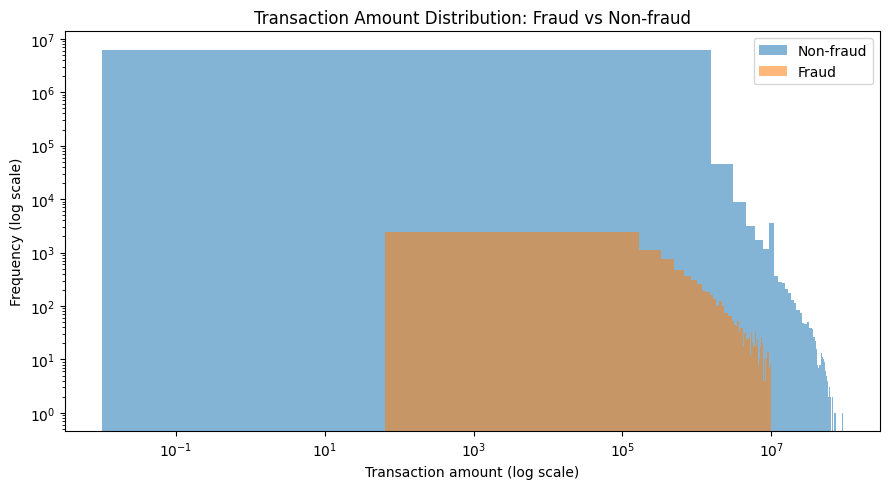

In [ ]:
# Transaction amount distribution on a logarithmic scale
import matplotlib.pyplot as plt

plot_data = analysis_df.loc[
    analysis_df["amount"] > 0, ["amount", "isFraud"]
].copy()

plt.figure(figsize=(9, 5))
for label, name in [(0, "Non-fraud"), (1, "Fraud")]:
    values = plot_data.loc[plot_data["isFraud"] == label, "amount"]
    plt.hist(values, bins=60, alpha=0.55, label=name)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Transaction amount (log scale)")
plt.ylabel("Frequency (log scale)")
plt.title("Transaction Amount Distribution: Fraud vs Non-fraud")
plt.legend()
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

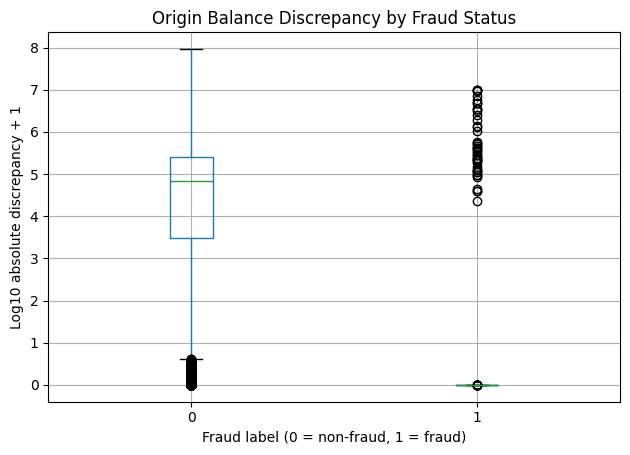

In [ ]:
# Origin balance discrepancy by fraud status
plot_data = analysis_df.dropna(
    subset=["origin_abs_discrepancy", "isFraud"]
).copy()

plot_data["log_origin_discrepancy"] = (
    plot_data["origin_abs_discrepancy"].clip(lower=0) + 1
).map(lambda x: __import__("math").log10(x))

plt.figure(figsize=(8, 5))
plot_data.boxplot(
    column="log_origin_discrepancy",
    by="isFraud"
)
plt.title("Origin Balance Discrepancy by Fraud Status")
plt.suptitle("")
plt.xlabel("Fraud label (0 = non-fraud, 1 = fraud)")
plt.ylabel("Log10 absolute discrepancy + 1")
plt.tight_layout()
plt.show()

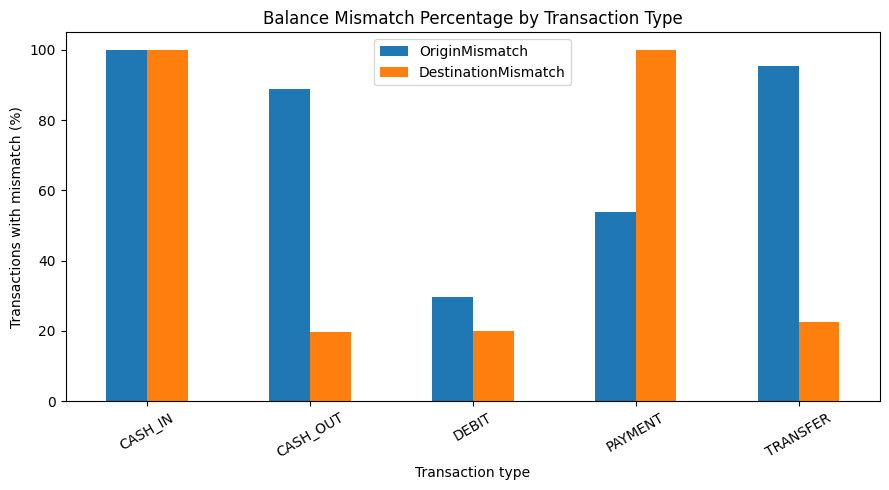

In [ ]:
# Transaction-type comparison of balance-mismatch prevalence
chart_data = analysis_df.groupby("type").agg(
    OriginMismatch=("origin_abs_discrepancy", lambda x: (x > 0.01).mean() * 100),
    DestinationMismatch=("destination_abs_discrepancy", lambda x: (x > 0.01).mean() * 100)
)

chart_data.plot(kind="bar", figsize=(9, 5))
plt.title("Balance Mismatch Percentage by Transaction Type")
plt.xlabel("Transaction type")
plt.ylabel("Transactions with mismatch (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

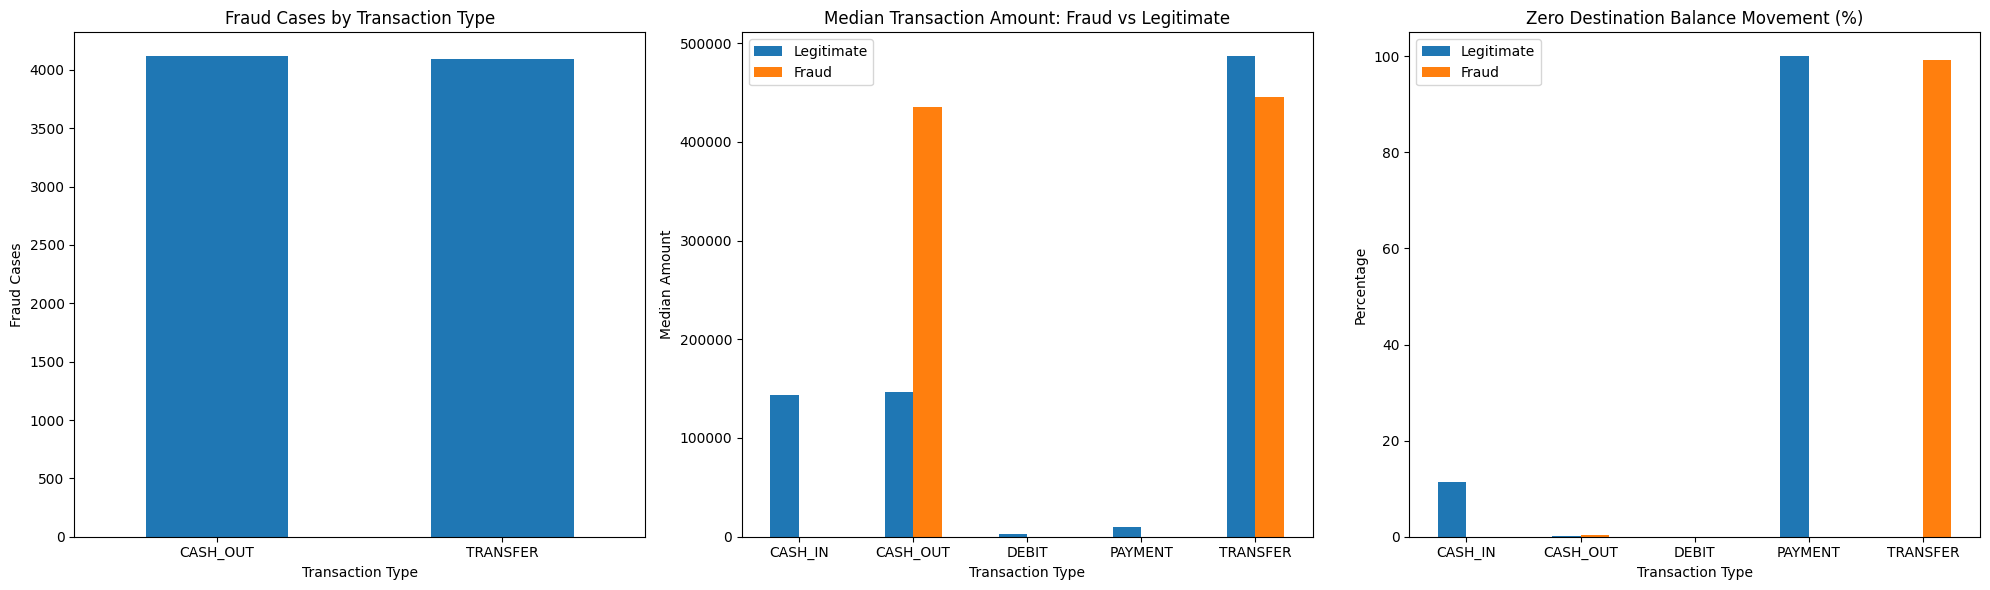

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Fraud cases by transaction type
fraud_counts = analysis_df[analysis_df["isFraud"] == 1].groupby("type").size()
fraud_counts.plot(kind="bar", ax=axes[0])
axes[0].set_title("Fraud Cases by Transaction Type")
axes[0].set_xlabel("Transaction Type")
axes[0].set_ylabel("Fraud Cases")
axes[0].tick_params(axis="x", rotation=0)

# 2. Median transaction amount: Fraud vs Legitimate
amount_profile = analysis_df.groupby(
    ["type", "isFraud"]
)["amount"].median().unstack()
amount_profile.plot(kind="bar", ax=axes[1])
axes[1].set_title("Median Transaction Amount: Fraud vs Legitimate")
axes[1].set_xlabel("Transaction Type")
axes[1].set_ylabel("Median Amount")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(["Legitimate", "Fraud"])

# 3. Zero destination balance movement comparison
zero_profile = analysis_df.groupby(
    ["type", "isFraud"]
)["destination_balance_change"].apply(
    lambda x: (x.abs() <= 0.01).mean() * 100
).unstack()

zero_profile.plot(kind="bar", ax=axes[2])
axes[2].set_title("Zero Destination Balance Movement (%)")
axes[2].set_xlabel("Transaction Type")
axes[2].set_ylabel("Percentage")
axes[2].tick_params(axis="x", rotation=0)
axes[2].legend(["Legitimate", "Fraud"])

plt.tight_layout()
plt.show()

In [ ]:
# Consolidated evidence for dashboard design
findings = pd.DataFrame([
    {
        "Analysis": "Balance consistency",
        "Metric": "Origin mismatch percentage",
        "Value": round((analysis_df["origin_abs_discrepancy"] > 0.01).mean() * 100, 2),
        "Unit": "%"
    },
    {
        "Analysis": "Balance consistency",
        "Metric": "Destination mismatch percentage",
        "Value": round((analysis_df["destination_abs_discrepancy"] > 0.01).mean() * 100, 2),
        "Unit": "%"
    },
    {
        "Analysis": "Anomaly investigation",
        "Metric": "Amount outlier count",
        "Value": int(analysis_df["amount_outlier"].sum()),
        "Unit": "transactions"
    },
    {
        "Analysis": "Detection review",
        "Metric": "Unflagged fraud count",
        "Value": int(len(missed_fraud)),
        "Unit": "transactions"
    }
])

display(findings)

,Analysis,Metric,Value,Unit
0,Balance consistency,Origin mismatch percentage,79.63,%
1,Balance consistency,Destination mismatch percentage,64.79,%
2,Anomaly investigation,Amount outlier count,339209.00,transactions
3,Detection review,Unflagged fraud count,8213.00,transactions


##Python EDA Overall Conclusion
The Python analysis provided deeper insights into transaction behaviour, balance inconsistencies, fraudulent patterns, and potential weaknesses in existing fraud controls. The findings indicate that fraudulent transactions have distinct characteristics, particularly within TRANSFER and CASH_OUT activities. However, balance discrepancies are not universal indicators of fraud and must be interpreted according to transaction type.
Key Findings and Insights
1. Balance inconsistencies: Origin mismatches affect 79.63% of transactions, while destination mismatches affect 64.79%. This highlights the need for transaction specific balance validation rather than assuming every mismatch is an error.

2. Fraud patterns: Fraudulent transactions generally have higher median amounts than legitimate transactions. TRANSFER fraud also shows a strong destination balance discrepancy pattern compared with legitimate transfers.

3. Anomaly investigation: 339,209 transactions exceed the legitimate transaction based IQR amount threshold, creating a substantial population for high value transaction review. These are potential outliers, not confirmed fraud cases.

4. Fraud control weakness: 8,213 fraudulent transactions were not flagged by the existing control, indicating a potential gap in fraud monitoring coverage, particularly for TRANSFER and CASH_OUT transactions.

5. Transaction behaviour: Zero balance movement and balance discrepancies reveal different patterns across transaction types, reinforcing the importance of analysing each type separately.